In [1]:
# Load the matched occupational dataset for analysis.
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/genai-human-skills-at-work/Occupational-level")

analysis_data = pd.read_csv(
    ROOT / "04_Analysis_Dataset" / "Output" / "Occupational_Analysis_Dataset.csv"
)

In [2]:
# Define analysis variables and count occupations by sector-assignment pattern.
outcome = "augmentation_share"

# Define the five skill bundles using the agreed descriptive names.
bundle_cols = [
    "Technical and analytical skills",
    "Critical thinking and evaluation",
    "Communication and interpersonal skills",
    "Complex problem solving and systems analysis",
    "Learning and time management",
]

sector_cols = [
    "sector_finance",
    "sector_healthcare",
    "sector_education",
    "sector_legal",
]

In [3]:
display(
    analysis_data[sector_cols]
    .value_counts(dropna=False)
    .rename("Occupations")
    .reset_index()
)

,sector_finance,sector_healthcare,sector_education,sector_legal,Occupations
0,False,True,True,False,181
1,False,False,True,False,126
2,True,True,True,False,116
3,True,True,True,True,107
4,False,True,False,False,22
5,True,False,False,False,10
6,False,True,True,True,5
7,True,True,False,True,5
8,True,False,True,False,4
9,True,False,True,True,3


In [4]:
# Retain occupations with complete outcome, bundle scores, and sector indicators.
required_cols = [outcome] + bundle_cols + sector_cols
analysis_sample = analysis_data.dropna(subset=required_cols).copy()

print(f"Matched occupations: {len(analysis_data)}")
print(f"Complete analysis sample: {len(analysis_sample)}")
print(f"Excluded for missing values: {len(analysis_data) - len(analysis_sample)}")

Matched occupations: 585
Complete analysis sample: 585
Excluded for missing values: 0


In [5]:
# Summarize task shares (%) and skill-bundle scores (1–5).
share_cols = ["automation_share", "augmentation_share", "limited_share"]

descriptive_data = analysis_sample[share_cols + bundle_cols].copy()
descriptive_data[share_cols] *= 100

descriptive_table = descriptive_data.agg(
    ["count", "mean", "std", "median", "min", "max"]
).T

descriptive_table.columns = ["N", "Mean", "SD", "Median", "Min", "Max"]
descriptive_table.insert(0, "Scale", ["%"] * 3 + ["1–5"] * len(bundle_cols))

descriptive_table = descriptive_table.rename(index={
    "automation_share": "Automation share",
    "augmentation_share": "Augmentation share",
    "limited_share": "Limited share",
})

display(descriptive_table.style.format({"N": "{:.0f}"}, precision=2))

,Scale,N,Mean,SD,Median,Min,Max
Automation share,%,585,5.17,7.00,3.12,0.00,46.67
Augmentation share,%,585,47.78,23.19,50.00,0.00,100.00
Limited share,%,585,47.06,25.24,44.00,0.00,100.00
Technical and analytical skills,1–5,585,1.98,0.42,1.92,1.10,3.48
Critical thinking and evaluation,1–5,585,3.03,0.36,3.05,1.77,4.10
Communication and interpersonal skills,1–5,585,3.20,0.41,3.25,2.16,4.25
Complex problem solving and systems analysis,1–5,585,2.99,0.50,3.06,1.50,4.12
Learning and time management,1–5,585,3.06,0.43,3.04,1.83,4.17


,Occupations
0% augmentation,6
Between 0% and 100%,576
100% augmentation,3


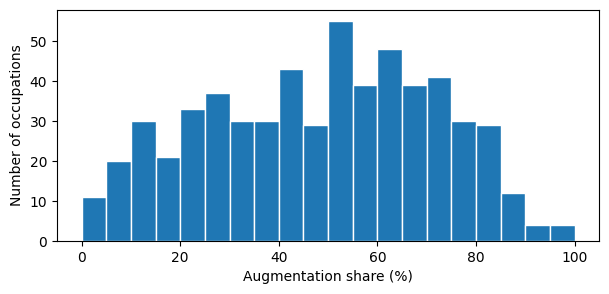

In [6]:
# Count augmentation-share endpoints and plot its distribution across occupations.
import matplotlib.pyplot as plt

augmentation = analysis_sample[outcome]

display(pd.Series({
    "0% augmentation": augmentation.eq(0).sum(),
    "Between 0% and 100%": augmentation.between(0, 1, inclusive="neither").sum(),
    "100% augmentation": augmentation.eq(1).sum(),
}, name="Occupations").to_frame())

(augmentation * 100).plot.hist(
    bins=20, range=(0, 100), figsize=(7, 3), edgecolor="white"
)
plt.xlabel("Augmentation share (%)")
plt.ylabel("Number of occupations")
plt.show()

In [7]:
# Summarize augmentation shares (%) by sector and task counts per occupation.
sector_summary = pd.DataFrame({
    sector.replace("sector_", "").title():
        analysis_sample.loc[analysis_sample[sector], outcome]
        .mul(100)
        .agg(["count", "mean", "std", "median", "min", "max"])
    for sector in sector_cols
}).T

sector_summary.columns = ["N", "Mean", "SD", "Median", "Min", "Max"]
display(sector_summary.style.format({"N": "{:.0f}"}, precision=2))

task_counts = analysis_sample["task_count"]
print(
    f"Tasks per occupation — Minimum: {task_counts.min()} | "
    f"Median: {task_counts.median():.1f} | Maximum: {task_counts.max()}"
)

,N,Mean,SD,Median,Min,Max
Finance,248,55.16,21.23,60.00,0.00,100.00
Healthcare,439,48.73,23.18,51.61,0.00,100.00
Education,543,48.44,23.07,50.00,0.00,100.00
Legal,124,61.28,18.64,62.50,0.00,100.00


Tasks per occupation — Minimum: 7 | Median: 21.0 | Maximum: 214


In [8]:
# Display Pearson correlations among occupational skill-bundle scores.
bundle_correlations = analysis_sample[bundle_cols].corr(method="pearson")

display(bundle_correlations.style.format("{:.2f}"))

,Technical and analytical skills,Critical thinking and evaluation,Communication and interpersonal skills,Complex problem solving and systems analysis,Learning and time management
Technical and analytical skills,1.00,0.76,0.25,0.71,0.45
Critical thinking and evaluation,0.76,1.00,0.61,0.89,0.75
Communication and interpersonal skills,0.25,0.61,1.00,0.73,0.86
Complex problem solving and systems analysis,0.71,0.89,0.73,1.00,0.81
Learning and time management,0.45,0.75,0.86,0.81,1.00


In [9]:
# Describe each bundle's association with augmentation share before sector adjustment.
augmentation_correlations = analysis_sample[bundle_cols].corrwith(
    analysis_sample[outcome], method="spearman"
).to_frame("Spearman rho")

display(augmentation_correlations.style.format("{:.2f}"))

,Spearman rho
Technical and analytical skills,0.33
Critical thinking and evaluation,0.44
Communication and interpersonal skills,0.55
Complex problem solving and systems analysis,0.62
Learning and time management,0.54


In [10]:
# Compare task shares and sector membership in matched and unmatched occupations.
rq1_data = pd.read_csv(
    ROOT / "01_Source_Data_Preparation/Input"
    / "Occupational_Task_Affordance_Configuration_v6.csv",
    dtype={"soc6": "string"}
)

rq1_data["Sample"] = rq1_data["soc6"].isin(
    analysis_sample["soc6"]
).map({True: "Matched", False: "Unmatched"})

display(rq1_data["Sample"].value_counts().to_frame("Occupations"))

sample_comparison = (
    rq1_data.groupby("Sample")[share_cols + sector_cols]
    .mean().mul(100).T
)
display(sample_comparison.style.format("{:.2f}"))

,Occupations
Sample,
Matched,585
Unmatched,186


Sample,Matched,Unmatched
automation_share,5.17,2.31
augmentation_share,47.78,24.91
limited_share,47.06,72.78
sector_finance,42.39,3.76
sector_healthcare,75.04,8.60
sector_education,92.82,9.68
sector_legal,21.20,3.23
